# Robot Navigation with a Markov Decision Process

*OxNet Access Programme (University of Oxford), 2025: Block 4 seminar lab*

A robot starts in room **d** and has to reach the goal room **c**. The rooms are connected by 7 doors, and some doors are unreliable: trying to go through them only works with a certain probability, otherwise the robot stays where it is. Every attempt costs time.

The question: **which door should the robot try in each room so that the expected total cost of reaching the goal is as low as possible?**

I model this as a Markov Decision Process (MDP) and solve it with **value iteration** using NumPy.

![Room layout](rooms.png)

In [1]:
import numpy as np
from typing import Any
from graphviz import Source

This notebook demonstrates the modelling and solving of a Markov decision process. The MDP is modelled using vectors and matrices. Each state in the MDP has a string label so we know which state we're working with, but for the model and solving algorithm we map that string to an index in a vector. 

# State Definitions

Each of our states is identified by a label. 

As described above, when we run value iteration (VI) we will not use the labels, we will use indexes in matrices. Below we define a function to do this.

In [2]:
state_labels = [
    "a",
    "b",
    "c",
    "d",
    "e",
    "f",
]

In [3]:
def enumerate_list(l: list[Any]) -> dict[str, int]:
    """Enumerate the items in a list. E.g. ["a", "b", "c"] is turned in to {"a":0, "b":1, "c":2]

    Args:
        l (list): A list of items

    Returns:
        map[str, int]: A dictionary mapping each item to an integer.
    """
    return {a: i for i, a in enumerate(l)}

We now use this function to map each state label to an integer.

In [4]:
states = enumerate_list(state_labels)
states

{'a': 0, 'b': 1, 'c': 2, 'd': 3, 'e': 4, 'f': 5}

# Actions

Each action is one of the 7 doors. Actions also have a label so we know which one we're talking about, but need to be mapped to an integer index too. We reuse the function from above to do this.

In [5]:
action_labels = [
    "door1",
    "door2",
    "door3",
    "door4",
    "door5",
    "door6",
    "door7",
]
actions = enumerate_list(action_labels)
actions

{'door1': 0, 'door2': 1, 'door3': 2, 'door4': 3, 'door5': 4, 'door6': 5, 'door7': 6}

# Costs

This section sets up the cost matrix $C(s,a)$. This demonstrates how we use the integer indexes defined above. We represent $C$ as a matrix (np.array) to map from an action (axis 0, or rows, in the matrix) to the cost of executing it in a particular state (axis 1, or columns, in the matrix). 

In [6]:
def create_empty_matrix(
    len_axis_0: int, len_axis_1: int, fill_value: np.float32 = np.inf
) -> np.ndarray[np.float32, np.float32]:
    """Create a 2D maxtrix filled with the provided value.

    Args:
        len_axis_0 (int): Number of rows in the matrix.
        len_axis_1 (int): Number of the columns in the matrix.
        fill_value (np.float32, optional): What to fill the matrix with.

    Returns:
        np.ndarray[np.float32, np.float32]: The created 2D matrix.
    """
    return np.full((len_axis_0, len_axis_1), fill_value=fill_value, dtype=np.float32)

Use the above code to create a matrix to store cost values. We fill it with `inf` so that all actions have infinite cost before we start filling them in later. We then specify costs only for the states where the actions are enabled. 

In [7]:
costs = create_empty_matrix(len(actions), len(states), fill_value=np.inf)
costs

array([[inf, inf, inf, inf, inf, inf],
       [inf, inf, inf, inf, inf, inf],
       [inf, inf, inf, inf, inf, inf],
       [inf, inf, inf, inf, inf, inf],
       [inf, inf, inf, inf, inf, inf],
       [inf, inf, inf, inf, inf, inf],
       [inf, inf, inf, inf, inf, inf]], dtype=float32)

We now define a function to set the cost for an action executed in a state. This is done to make the code more readable.

In [8]:
def set_cost(
    c: np.ndarray[np.float32, np.float32],
    a_label: str,
    s_label: str,
    cost: np.float32,
    state_mapping: dict[str, int] = states,
    action_mapping: dict[str, int] = actions,
) -> None:
    """Set the cost of an action in the the given state in the provided cost matrix.

    Args:
        c (np.ndarray[np.float32, np.float32]): The cost matrix.
        a_label (str): The label of the action.
        s_label (str): The label of the state.

        cost (np.float32): The cost of taking the action in the state.
        state_mapping (dict[str, int], optional): The dict that maps the state label to an index. Defaults to states.
        action_mapping (dict[str, int], optional): The dict that maps the action label to an index. Defaults to actions.
    """
    c[action_mapping[a_label], state_mapping[s_label]] = cost

# Transitions

The transition functions $T(s,a)$ are set up to provide transitions for all states to all other states. Each action has one transition function matrix. The transition function matrix represents the probability of transitioning from $s$ to $s'$ under the action. In an action transition function matrix the rows (axis 0) correspond to the starting state ($s$) and the columns to the resultant state ($s'$). The cell $s, s'$ contains the probability of ending up in $s'$ from $s$ given the action was taken.

In [9]:
def set_transition_probability(
    t: np.ndarray[np.float32, np.float32],
    s_label: str,#current state'
    sp_label: str,#'state after action'
    p: np.float32,#probability
    state_mapping: dict[str, int] = states,
) -> None:
    t[state_mapping[s_label], state_mapping[sp_label]] = p

# MDP Construction

Now I set up the transition matrix and cost for each door. Each door only works from certain rooms, and some doors can fail (the robot stays in the same room).

**Door 1** (d → a): succeeds with probability 0.9, otherwise the robot stays in d. Cost 2.

In [10]:
# door 1
t_door1 = create_empty_matrix(len(states), len(states), fill_value=0)
set_transition_probability(t_door1, "d", "a", 0.9) #from d to a 
set_cost(costs,"door1","d",2)
set_transition_probability(t_door1, "d", "d", 0.1)# stayed d
set_cost(costs,"door1","d",2)

**Door 2** (a → b): succeeds with probability 0.7, otherwise the robot stays in a. Cost 2.

In [11]:
# door 2
t_door2 = create_empty_matrix(len(states), len(states), fill_value=0)
set_transition_probability(t_door2, "a", "b", 0.7) #from a to b 
set_cost(costs,"door2","a",2)
set_transition_probability(t_door2, "a", "a", 0.3)#stayed a
set_cost(costs,"door2","a",2)

**Door 3** (d → e): succeeds with probability 0.7, otherwise the robot stays in d. Cost 2.

In [12]:
# door 3
t_door3 = create_empty_matrix(len(states), len(states), fill_value=0)
set_transition_probability(t_door3, "d", "e", 0.7) #from d to e
set_cost(costs,"door3","d",2)
set_transition_probability(t_door3, "d", "d", 0.3)#stayed d
set_cost(costs,"door3","d",2)

**Door 4** (b ↔ e): always works, in both directions. Cost 1.

In [13]:
# door 4
t_door4 = create_empty_matrix(len(states), len(states), fill_value=0)
set_transition_probability(t_door4, "b", "e", 1) #from b to e 
set_cost(costs,"door4","b",1)
set_transition_probability(t_door4, "e", "b", 1) # from e to b
set_cost(costs,"door4","e",1)

**Door 5** (b → c, the goal): always works. Cost 1.

In [14]:
# door 5
t_door5 = create_empty_matrix(len(states), len(states), fill_value=0)
set_transition_probability(t_door5, "b", "c", 1) # from b to c (the goal)
set_cost(costs, "door5", "b", 1)

**Door 6** (e ↔ f): always works, in both directions. Cost 1.

In [15]:
# door 6
t_door6 = create_empty_matrix(len(states), len(states), fill_value=0)
set_transition_probability(t_door6, "e", "f", 1) #from e to f
set_cost(costs,"door6","e",1)
set_transition_probability(t_door6, "f", "e", 1) # from f to e
set_cost(costs,"door6","f",1)

**Door 7** (f → c, the goal): succeeds with probability 0.9, otherwise the robot stays in f. Cost 2.

In [16]:
# door 7
t_door7 = create_empty_matrix(len(states), len(states), fill_value=0)
set_transition_probability(t_door7, "f", "c", 0.9) #from f to c 
set_cost(costs,"door7","f",2)
set_transition_probability(t_door7, "f", "f", 0.1) #stayed f  
set_cost(costs,"door7","f",2)

We set all of the actions taken in the goal state to have a cost of zero. This means that the value of the goal state cannot be changed by an action. This is a convenience for use in value iteration.

In [17]:
goal_label = "c"
# the ":" slices the array to select all rows
costs[:, states[goal_label]] = 0
costs

array([[inf, inf,  0.,  2., inf, inf],
       [ 2., inf,  0., inf, inf, inf],
       [inf, inf,  0.,  2., inf, inf],
       [inf,  1.,  0., inf,  1., inf],
       [inf,  1.,  0., inf, inf, inf],
       [inf, inf,  0., inf,  1.,  1.],
       [inf, inf,  0., inf, inf,  2.]], dtype=float32)

Next we store all the transition functions in a matrix so we can evaluate them all through one matrix operation. 

In [18]:
transitions = np.zeros((len(actions), len(states), len(states)))

transitions[actions["door1"]] = t_door1
transitions[actions["door2"]] = t_door2
transitions[actions["door3"]] = t_door3
transitions[actions["door4"]] = t_door4
transitions[actions["door5"]] = t_door5
transitions[actions["door6"]] = t_door6
transitions[actions["door7"]] = t_door7

Print out final cost matrix

In [19]:
costs

array([[inf, inf,  0.,  2., inf, inf],
       [ 2., inf,  0., inf, inf, inf],
       [inf, inf,  0.,  2., inf, inf],
       [inf,  1.,  0., inf,  1., inf],
       [inf,  1.,  0., inf, inf, inf],
       [inf, inf,  0., inf,  1.,  1.],
       [inf, inf,  0., inf, inf,  2.]], dtype=float32)

It is useful (e.g. in the visualisation code below) to see which actions are *enabled* in a state. Enabled means that the action leads to other states with a non-zero probability.

In [20]:
def enabled_actions(t: np.ndarray, s_idx: int) -> np.ndarray[int]:
    """Get a list of indexes of actions that are enabled in the given state.

    Args:
        t (np.ndarray): MDP transition matrix
        s_idx (int): Index of state to check for enabled actions.

    Returns:
        np.ndarray[int]: Array of indexes of enabled actions
    """
    return np.nonzero(t[:, s_idx].sum(axis=1))[0]

Test the above code for the start room, d.

In [21]:
state_label = "d"
for action_idx in enabled_actions(transitions, states[state_label]):
    print(f"{action_labels[action_idx]} is enabled in {state_label}")

door1 is enabled in d
door3 is enabled in d


# Visualising the MDP

We can use Graphviz to visualise the MDP. This is useful for debugging the model. The following code iterates through the MDP and creates the "dot" string which is then converted into a Graphviz object. You do not need to understand it!

In [22]:
def visualise_mdp(
    t: np.ndarray,
    c: np.ndarray,
    s_labels: list[str] = state_labels,
    a_labels: list[str] = action_labels,
    title: str = None,
) -> Source:
    """Convert the MDP to a Graphviz source object for visualisation.

    Args:
        t (np.ndarray): Full MDP transition matrix..
        c (np.ndarray): Full MDP cost matrix
        s_labels (list[str], optional): List of state labels. Defaults to state_labels.
        a_labels (list[str], optional): List of action labels. Defaults to action_labels.
        title (str, optional): Title for the visualisation. Defaults to None.

    Returns:
        Source: _description_
    """
    # Formatting for the "hidden" nodes on the action edge
    action_format = 'style=filled, fillcolor=black, fixedsize=true, width=0.05, height=0.05, label="", fontsize=0'

    dot_string = ""

    dot_string += "digraph graphname {\n"
    if title:
        dot_string += f'\n\n\tlabel="{title}";\n\nlabelloc=t;\n\n'

    counter = 0

    for state_idx, state_label in enumerate(s_labels):
        # Actions from state
        # shape = "doubleoctagon"
        shape = "ellipse"

        action_indexes = enabled_actions(t, state_idx)

        # Node for state
        dot_string += f'\n\n\t{state_label} [shape="{shape}" label="{state_label}"'
        dot_string += "];\n\n"

        for action_idx in action_indexes:
            # indexes of states with non-zero transitions
            successors = np.nonzero(transitions[action_idx][state_idx])[0]

            if len(successors) > 1:
                # Add the node which is in the middle of the action
                # dot_string += f'\t"{action}_{counter}" [{action_format}];\n'
                dot_string += f'\t"{action_idx}_{counter}" [{action_format}];\n'
                # Add the edge between the state and the middle of action node
                dot_string += f'\t{state_label} -> "{action_idx}_{counter}" [arrowhead=none, label="{a_labels[action_idx]}, C={c[action_idx,state_idx]:.0f}"];\n\n'
                # f'\t{state_label.__hash__()} -> "{action}_{counter}" [arrowhead=none, label="{action}"];\n\n'
                # Add actions from middle of action node to successor nodes
                for successor_idx in successors:
                    dot_string += f'\t"{action_idx}_{counter}" -> {state_labels[successor_idx]} [label="{t[action_idx,state_idx,successor_idx]:.1f}"];\n'
                    # f'\t"{action}_{counter}" -> {successor.__hash__()} [label="{successor_prob:.3f}, R={self.get_reward(state, action, successor):.3f}"];\n'
            else:
                for successor_idx in successors:
                    dot_string += f'\t"{state_label}" -> {state_labels[successor_idx]} [label="{a_labels[action_idx]}, C={c[action_idx,state_idx]:.0f}"];\n'
            counter += 1

    dot_string += "\n\n}"
    return Source(dot_string)

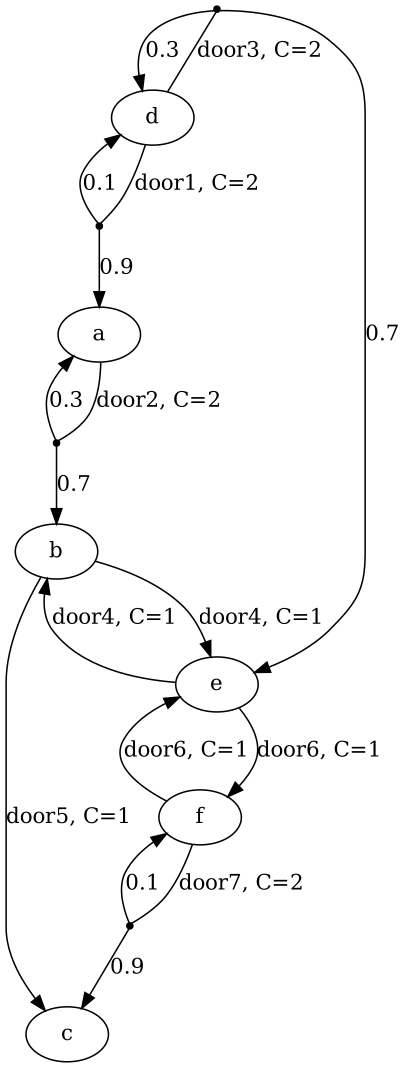

In [23]:
visualise_mdp(transitions, costs, state_labels, action_labels)

# Value Iteration

Value iteration operates on vector of values, where each value represents the expected cost to reach the goal from that state. The following function creates a value vector, with a default value for each state.



In [24]:
def create_value_vector(
    fill_with: int, s_labels: list[Any] = state_labels
) -> np.ndarray[np.float32]:
    """Create a vector of values matching the length of a state vector.

    Args:
        fill_with (int): The initialisation value.
        s_labels (list[Any], optional): An array-like object that is used to provide the shape of the value vector. Defaults to state_labels.

    Returns:
        np.ndarray[np.float32]: The value vector.
    """
    return np.full_like(s_labels, fill_with, dtype=np.float32)

Next we create a vector of initial state values. These should be greater than zero, and can be arbitrarily large. 

In [25]:
v_init = create_value_vector(100)
v_init

array([100., 100., 100., 100., 100., 100.], dtype=float32)

Since we know the goal state, we can set the value of that to zero, since it has no cost.

In [26]:
v_init[states[goal_label]] = 0
v_init

array([100., 100.,   0., 100., 100., 100.], dtype=float32)

The core of value iteration (VI) is the operation below. This multiplies a vector of state values ($v_{n-1}$) by the transition function, then adds the costs. This gives a matrix of $Q(s, a)$ values, where each row contains a list of Q values per action, and each column is the Q value for that action reaching that state.

In [27]:
q_matrix = np.dot(transitions, v_init) + costs #rows are actions columns are q value 
q_matrix

array([[         inf,          inf,   0.        , 101.99999776,
                 inf,          inf],
       [102.        ,          inf,   0.        ,          inf,
                 inf,          inf],
       [         inf,          inf,   0.        , 102.        ,
                 inf,          inf],
       [         inf, 101.        ,   0.        ,          inf,
        101.        ,          inf],
       [         inf,   1.        ,   0.        ,          inf,
                 inf,          inf],
       [         inf,          inf,   0.        ,          inf,
        101.        , 101.        ],
       [         inf,          inf,   0.        ,          inf,
                 inf,  12.00000015]])

We calculate the next state value vector by selecting the minimum cost action in each state. In code this corresponds to looking for the minimum value a min along the columns.

In [28]:
np.min(q_matrix, axis=0)

array([102.        ,   1.        ,   0.        , 101.99999776,
       101.        ,  12.00000015])

To get the action index (needed for the policy) from the minimum operation we use `argmin` to get the "argument" (i.e. index) which provides in the minimum via `argmin`.

In [29]:
np.argmin(q_matrix, axis=0)

array([1, 4, 0, 0, 3, 6])

During VI we keep track of the previous value vector using `v_prev`. We do this for the initial value below.

In [30]:
v_prev = v_init

Define `epsilon` which gives us our stopping condition.

In [31]:
epsilon = 1e-05

And finally, run value iteration and extract the policy.

In [32]:
# keep track of the largest residual seen
max_residual = 100

# while the max residual is not small enough to stop
while max_residual > epsilon:
    # create the new Q(s,a) matrix
    q_matrix = np.dot(transitions, v_prev) + costs #q value
    # update value vector using the minimum cost action for each state
    v_next = np.min(q_matrix, axis=0) 
    # calculate max residual different in value vector
    max_residual = np.max(np.abs(v_next - v_prev))
    # store the value vector
    v_prev = v_next
    # and print max residual
    print(f"max. residual: {max_residual}")

# extract policy
policy = np.argmin(q_matrix, axis=0)

max. residual: 99.0
max. residual: 99.0
max. residual: 68.90999833136796
max. residual: 20.67300032088158
max. residual: 6.201900342705843
max. residual: 1.860570176744166
max. residual: 0.5581710752029743
max. residual: 0.16745132921481076
max. residual: 0.050235400760618276
max. residual: 0.015070620827037473
max. residual: 0.004521186427767887
max. residual: 0.001356355982226276
max. residual: 0.0004069068108378815
max. residual: 0.00012207204810188443
max. residual: 3.662161588557922e-05
max. residual: 1.0986485202479912e-05
max. residual: 3.295945691483837e-06


We can then inspect the policy

In [33]:
for state_label, s in states.items():
    if state_label != goal_label:
        print(f"in state {state_label} choose {action_labels[policy[s]]}")

in state a choose door2
in state b choose door5
in state d choose door3
in state e choose door4
in state f choose door7


And also check the value of the states

In [34]:
for state_label, s in states.items():
    print(f"the value of state {state_label} is {v_next[s]}")


the value of state a is 3.857143328272798
the value of state b is 1.0
the value of state c is 0.0
the value of state d is 4.857144318347944
the value of state e is 2.0
the value of state f is 2.2222222259015223


# Result

Starting in room **d**, the optimal policy is:

**d → door 3 → e → door 4 → b → door 5 → c (goal)**

with an expected cost of about **4.86**.

The route through room a (d → door 1 → a → door 2 → b → door 5 → c) is *not* the best: it passes through two unreliable doors, so its expected cost is about 2/0.9 + 2/0.7 + 1 ≈ 6.08. Going via e only has one unreliable door (door 3), giving 2/0.7 + 1 + 1 ≈ 4.86. Value iteration finds this automatically by repeatedly updating the expected cost of every room until the values stop changing (here it converges after 17 iterations).

**What I learned:** how to model decision-making under uncertainty as an MDP (states, actions, transition probabilities and costs), how to represent it with NumPy matrices, and how value iteration uses the Bellman update to find an optimal policy.